# HealthyAir - Data Exploration for calculation, visualisation and interpretation.
### Examines the dataset structure, data types, missing values, distributions, 
### correlations and time patterns.

### Expected input: data/raw/AirQualityUCI.csv

### The original UCI file is commonly semicolon-separated, uses decimal commas, and 
### encodes missing readings as -200. 
### Check downloaded copy and keep the raw file unchanged.

In [1]:
# Import Libraries
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import statsmodels
import scipy
import os
import gcsfs

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("statsmodels:", statsmodels.__version__)

Python: 3.12.3
NumPy: 2.5.3
pandas: 3.0.6
SciPy: 1.18.1
Matplotlib: 3.11.1
Seaborn: 0.13.2
statsmodels: 0.15.0


In [ ]:
#Load data
#df = pd.read_csv("data/raw/AirQualityUCI.csv")
#print("Data loaded successfully.")
#print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
#display(df.head())

In [2]:
# Confirm location
print(sys.executable)

/home/chloekc/datahandling/healthyair/.venv/bin/python


In [3]:
# Load data from Google Cloud Storage
GCS_PROJECT_ID = "128630137158"
GCS_BUCKET = "uci_air_quality_20119102"
GCS_FILE = "gs://uci_air_quality_20119102/data_raw/AirQualityUCI.csv"
df = pd.read_csv(GCS_FILE)

print("Dataset path:", GCS_BUCKET)
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}")
display(df.head())

Dataset path: uci_air_quality_20119102
Rows: 9,471; columns: 17


,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,3/10/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,3/10/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,3/10/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,3/10/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,3/10/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   str    
 1   Time           9357 non-null   str    
 2   CO(GT)         9357 non-null   float64
 3   PT08.S1(CO)    9357 non-null   float64
 4   NMHC(GT)       9357 non-null   float64
 5   C6H6(GT)       9357 non-null   float64
 6   PT08.S2(NMHC)  9357 non-null   float64
 7   NOx(GT)        9357 non-null   float64
 8   PT08.S3(NOx)   9357 non-null   float64
 9   NO2(GT)        9357 non-null   float64
 10  PT08.S4(NO2)   9357 non-null   float64
 11  PT08.S5(O3)    9357 non-null   float64
 12  T              9357 non-null   float64
 13  RH             9357 non-null   float64
 14  AH             9357 non-null   float64
 15  Unnamed: 15    0 non-null      float64
 16  Unnamed: 16    0 non-null      float64
dtypes: float64(15), str(2)
memory usage: 1.2 MB


In [9]:
df.describe()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
count,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,9357.000000,0.0,0.0
mean,-34.207524,1048.990061,-159.090093,1.865683,894.595276,168.616971,794.990168,58.148873,1391.479641,975.072032,9.778305,39.485380,-6.837604,NaN,NaN
std,77.657170,329.832710,139.789093,41.380206,342.333252,257.433866,321.993552,126.940455,467.210125,456.938184,43.203623,51.216145,38.976670,NaN,NaN
min,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,-200.000000,NaN,NaN
25%,0.600000,921.000000,-200.000000,4.000000,711.000000,50.000000,637.000000,53.000000,1185.000000,700.000000,10.900000,34.100000,0.692300,NaN,NaN
50%,1.500000,1053.000000,-200.000000,7.900000,895.000000,141.000000,794.000000,96.000000,1446.000000,942.000000,17.200000,48.600000,0.976800,NaN,NaN
75%,2.600000,1221.000000,-200.000000,13.600000,1105.000000,284.000000,960.000000,133.000000,1662.000000,1255.000000,24.100000,61.900000,1.296200,NaN,NaN
max,11.900000,2040.000000,1189.000000,63.700000,2214.000000,1479.000000,2683.000000,340.000000,2775.000000,2523.000000,44.600000,88.700000,2.231000,NaN,NaN


In [14]:
print("Date range:")
print(df["Date"].min(), "to", df["Date"].max())

display(df[["Date", "Time"]].head(10))

Date range:
1/1/2005 to 9/9/2004


,Date,Time
0,3/10/2004,18:00:00
1,3/10/2004,19:00:00
2,3/10/2004,20:00:00
3,3/10/2004,21:00:00
4,3/10/2004,22:00:00
5,3/10/2004,23:00:00
6,3/11/2004,0:00:00
7,3/11/2004,1:00:00
8,3/11/2004,2:00:00
9,3/11/2004,3:00:00


In [10]:
# Schema, types and missingness
display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str)}))
missing = df.isna().sum().sort_values(ascending=False)
display(pd.DataFrame({"missing_count": missing, "missing_percent": (missing / len(df) * 100).round(2)}))
display(df.describe(include="all").T)

,column,dtype
Date,Date,str
Time,Time,str
CO(GT),CO(GT),float64
PT08.S1(CO),PT08.S1(CO),float64
NMHC(GT),NMHC(GT),float64
C6H6(GT),C6H6(GT),float64
PT08.S2(NMHC),PT08.S2(NMHC),float64
NOx(GT),NOx(GT),float64
PT08.S3(NOx),PT08.S3(NOx),float64
NO2(GT),NO2(GT),float64


,missing_count,missing_percent
Unnamed: 16,9471,100.0
Unnamed: 15,9471,100.0
Date,114,1.2
Time,114,1.2
CO(GT),114,1.2
C6H6(GT),114,1.2
PT08.S2(NMHC),114,1.2
PT08.S1(CO),114,1.2
NMHC(GT),114,1.2
PT08.S3(NOx),114,1.2


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,9357,391,3/11/2004,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9357,24,18:00:00,390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CO(GT),9357.0,NaN,NaN,NaN,-34.207524,77.65717,-200.0,0.6,1.5,2.6,11.9
PT08.S1(CO),9357.0,NaN,NaN,NaN,1048.990061,329.83271,-200.0,921.0,1053.0,1221.0,2040.0
NMHC(GT),9357.0,NaN,NaN,NaN,-159.090093,139.789093,-200.0,-200.0,-200.0,-200.0,1189.0
C6H6(GT),9357.0,NaN,NaN,NaN,1.865683,41.380206,-200.0,4.0,7.9,13.6,63.7
PT08.S2(NMHC),9357.0,NaN,NaN,NaN,894.595276,342.333252,-200.0,711.0,895.0,1105.0,2214.0
NOx(GT),9357.0,NaN,NaN,NaN,168.616971,257.433866,-200.0,50.0,141.0,284.0,1479.0
PT08.S3(NOx),9357.0,NaN,NaN,NaN,794.990168,321.993552,-200.0,637.0,794.0,960.0,2683.0
NO2(GT),9357.0,NaN,NaN,NaN,58.148873,126.940455,-200.0,53.0,96.0,133.0,340.0


In [11]:
# Timestamps
work = df.copy()
if {"Date", "Time"}.issubset(work.columns):
    work["timestamp"] = pd.to_datetime(work["Date"].astype(str) + " " + work["Time"].astype(str),
                                       dayfirst=True, errors="coerce")
    print("Invalid timestamps:", work.timestamp.isna().sum())
    print("Duplicate timestamps:", work.timestamp.duplicated().sum())
    print("Range:", work.timestamp.min(), "to", work.timestamp.max())
    display((work.timestamp.sort_values().diff().value_counts().head(10)).to_frame("count"))
else:
    print("Date/Time columns not found. Check the actual source schema.")

Invalid timestamps: 5874
Duplicate timestamps: 5873
Range: 2004-01-04 00:00:00 to 2005-12-03 23:00:00


,count
timestamp,
0 days 01:00:00,3573
22 days 01:00:00,5
27 days 01:00:00,5
28 days 01:00:00,4
21 days 01:00:00,3
20 days 01:00:00,2
20 days 19:00:00,1
19 days 01:00:00,1
24 days 01:00:00,1


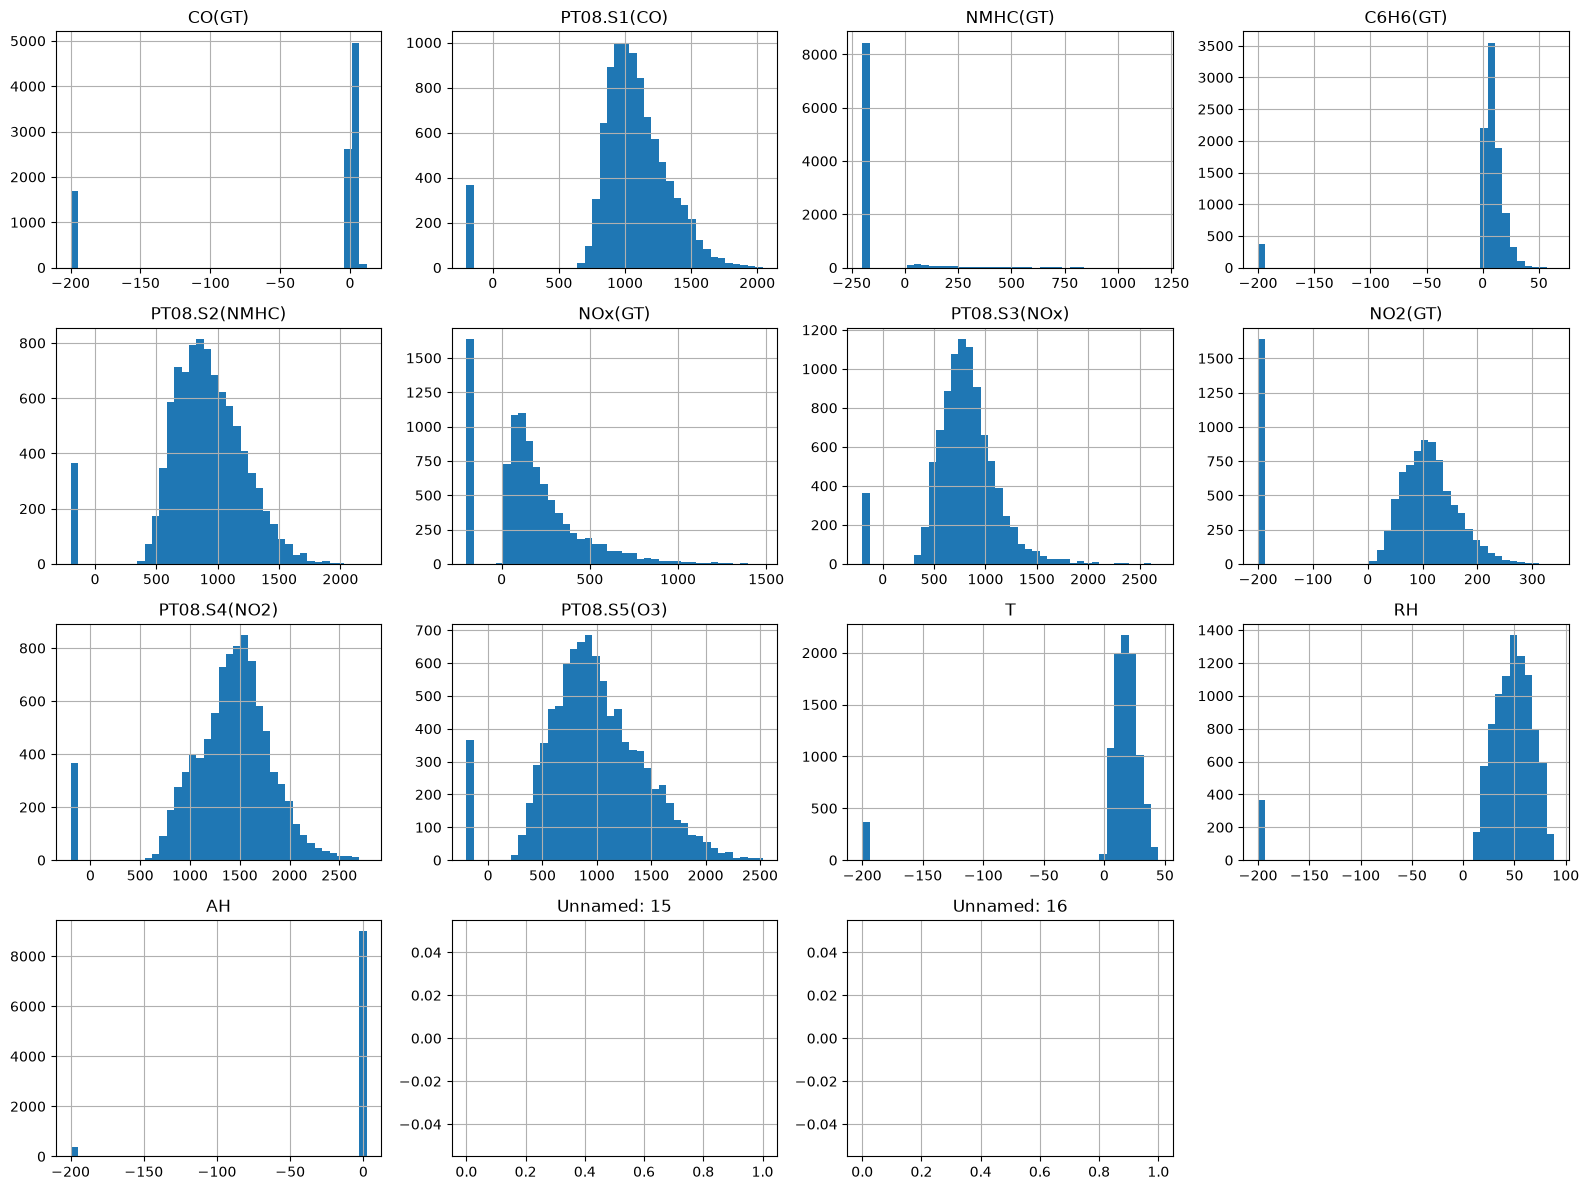

In [12]:
# Measurement Distributions
numeric = work.select_dtypes(include="number")
numeric.hist(figsize=(16, 12), bins=40)
plt.tight_layout()
plt.show()

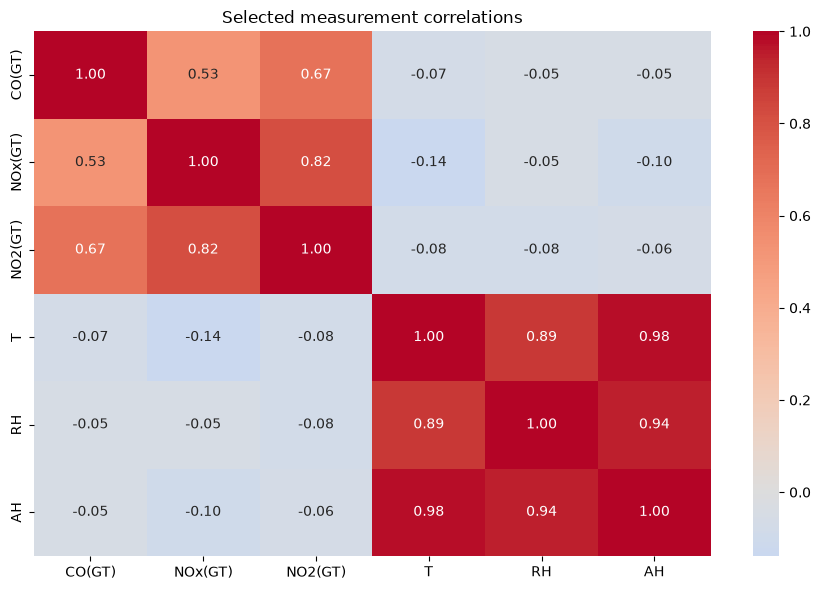

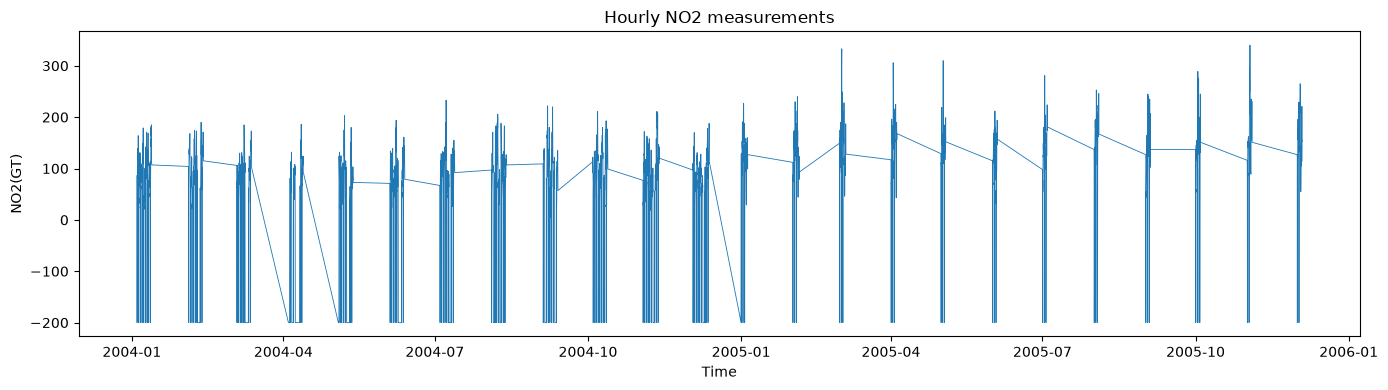

In [13]:
# Relationships
selected = [c for c in ["CO(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"] if c in work.columns]
if len(selected) > 1:
    plt.figure(figsize=(9, 6))
    sns.heatmap(work[selected].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f")
    plt.title("Selected measurement correlations")
    plt.tight_layout()
    plt.show()

if "timestamp" in work and "NO2(GT)" in work:
    p = work[["timestamp", "NO2(GT)"]].dropna().sort_values("timestamp")
    plt.figure(figsize=(14, 4))
    plt.plot(p.timestamp, p["NO2(GT)"], linewidth=.6)
    plt.xlabel("Time"); plt.ylabel("NO2(GT)")
    plt.title("Hourly NO2 measurements")
    plt.tight_layout(); plt.show()

In [ ]:
variable_roles = pd.DataFrame({
    "variable": [],
    "analytical_role": [],
    "suitable_summary": []
})
display(variable_roles)


In [15]:
# Schema & semantic roles

schema_audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "missing": df.isna().sum(),
    "unique": df.nunique(dropna=True)
}).sort_values("missing", ascending=False)
display(schema_audit)


,dtype,non_null,missing,unique
Unnamed: 16,float64,0,9471,0
Unnamed: 15,float64,0,9471,0
Date,str,9357,114,391
Time,str,9357,114,24
CO(GT),float64,9357,114,97
C6H6(GT),float64,9357,114,408
PT08.S2(NMHC),float64,9357,114,1246
PT08.S1(CO),float64,9357,114,1042
NMHC(GT),float64,9357,114,430
PT08.S3(NOx),float64,9357,114,1222


In [16]:
# Missing Values
missing = (
    df.isnull()
      .sum()
      .sort_values(ascending=False)
)

missing[missing > 0]

Unnamed: 16      9471
Unnamed: 15      9471
Date              114
Time              114
CO(GT)            114
C6H6(GT)          114
PT08.S2(NMHC)     114
PT08.S1(CO)       114
NMHC(GT)          114
PT08.S3(NOx)      114
NOx(GT)           114
NO2(GT)           114
PT08.S4(NO2)      114
T                 114
PT08.S5(O3)       114
AH                114
RH                114
dtype: int64

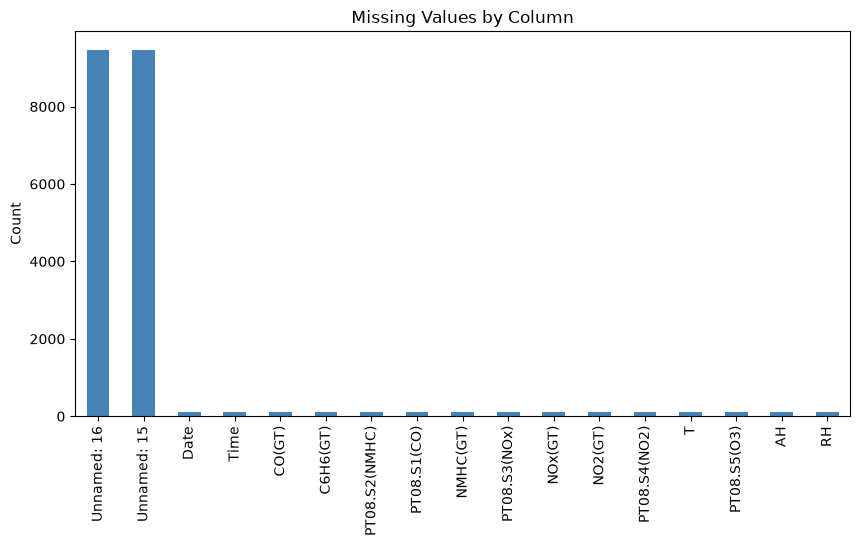

In [17]:
# Visualize
plt.figure(figsize=(10, 5))

missing[missing > 0].plot(
    kind="bar",
    color="steelblue"
)

plt.title("Missing Values by Column")
plt.ylabel("Count")
plt.show()

In [18]:
# Duplicate Records
duplicates = df.duplicated().sum()

print(f"Duplicate rows: {duplicates}")

Duplicate rows: 113


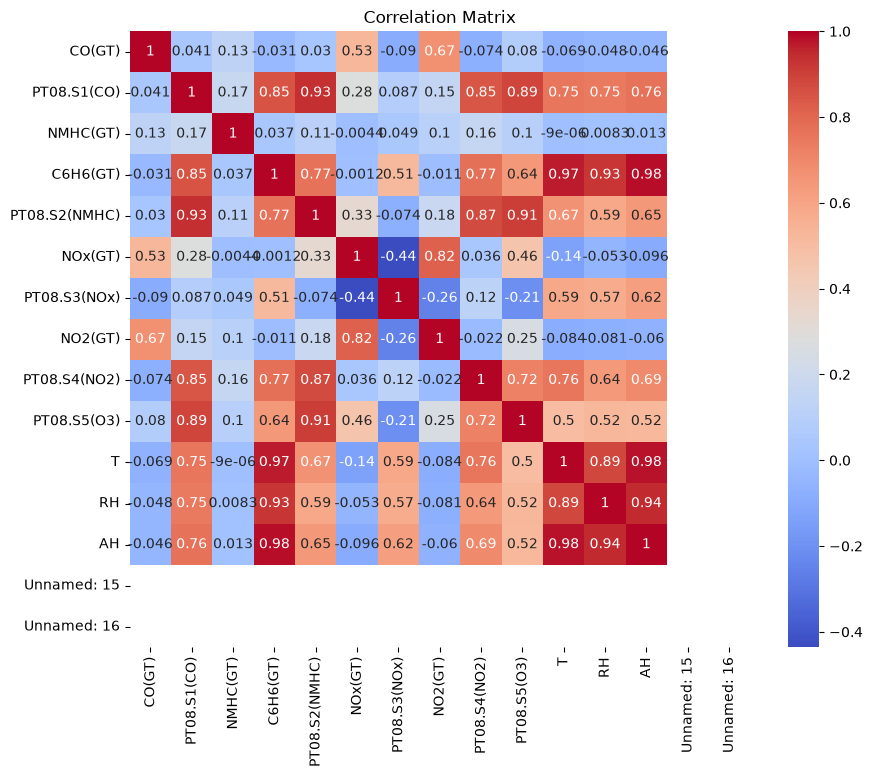

In [19]:
# Correlations
numeric_cols = df.select_dtypes(include="number").columns
plt.figure(figsize=(10, 8))

sns.heatmap(
    df[numeric_cols].corr(),
    cmap="coolwarm",
    annot=True
)

plt.title("Correlation Matrix")
plt.show()

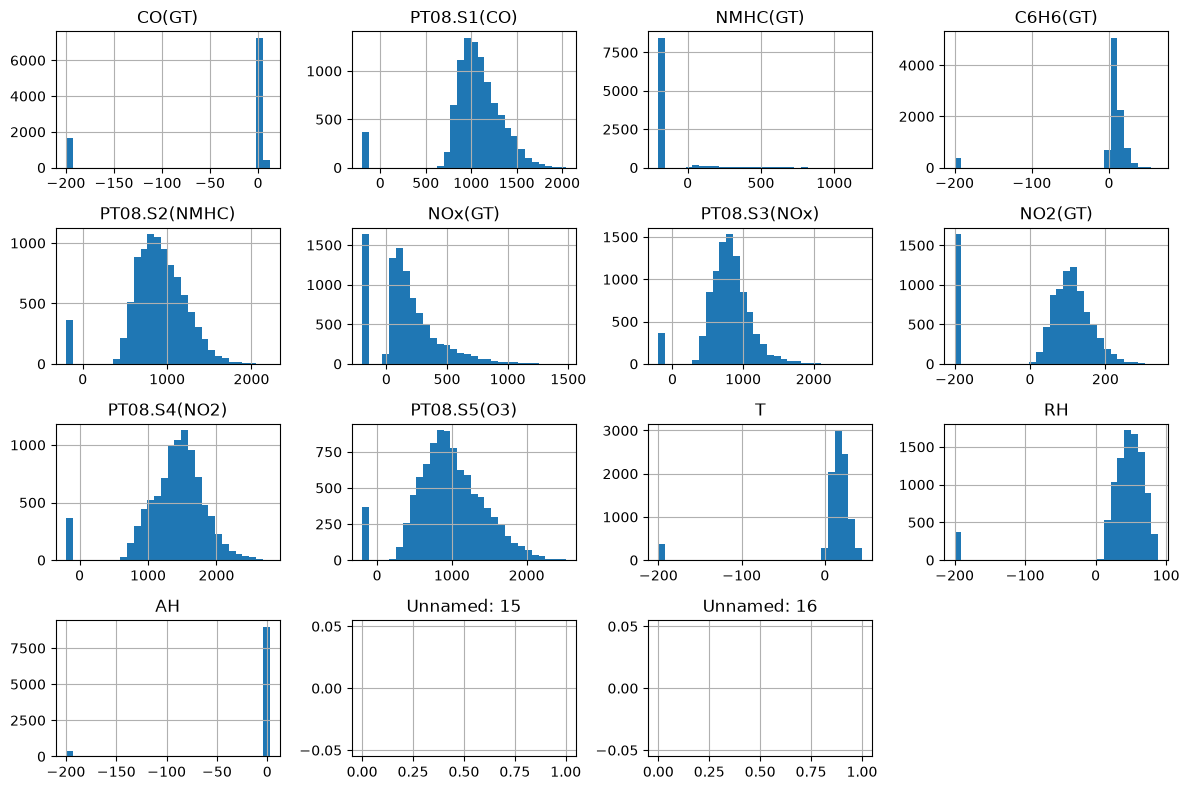

In [20]:
# Distributions
numeric_cols = df.select_dtypes(
    include=np.number
).columns

df[numeric_cols].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

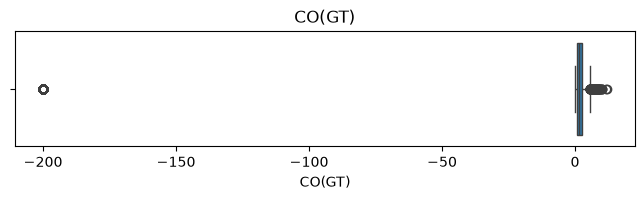

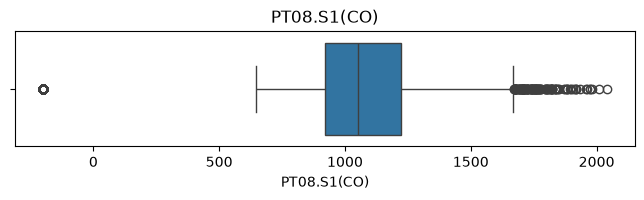

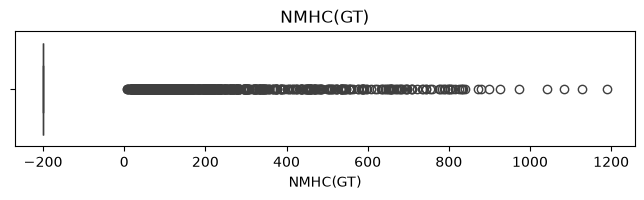

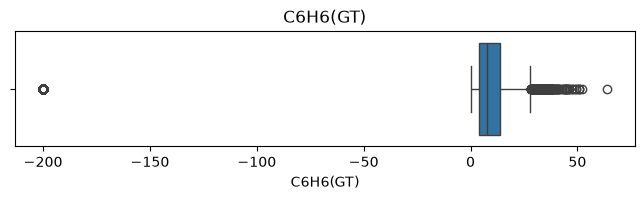

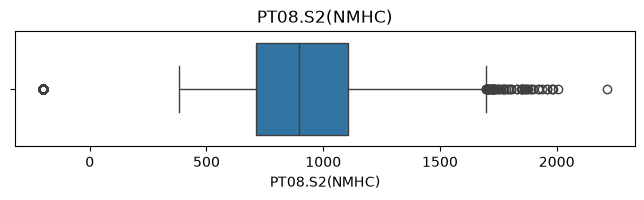

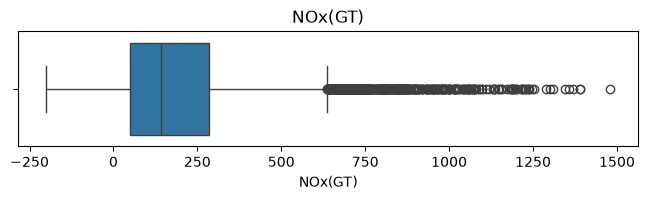

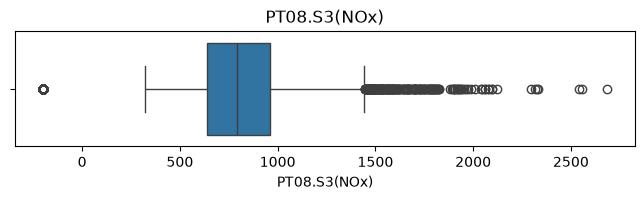

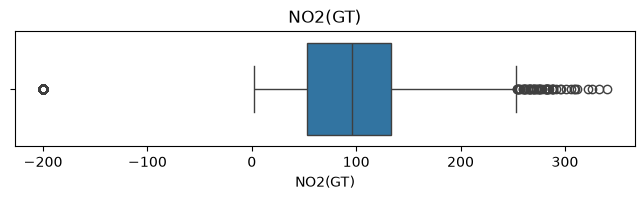

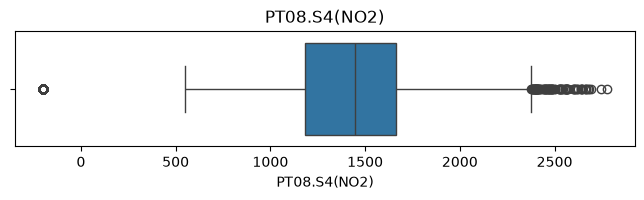

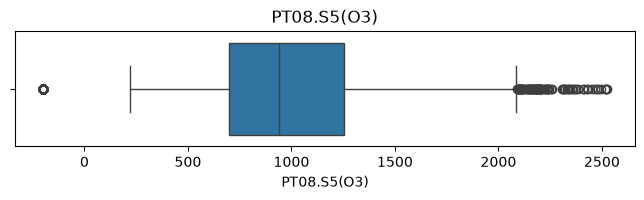

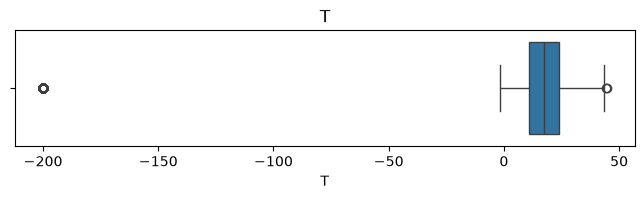

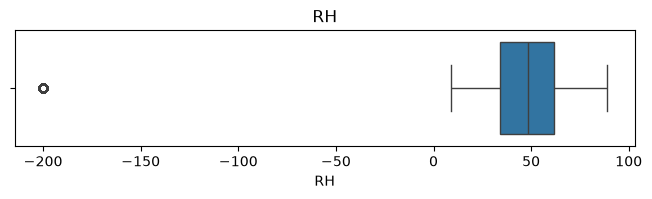

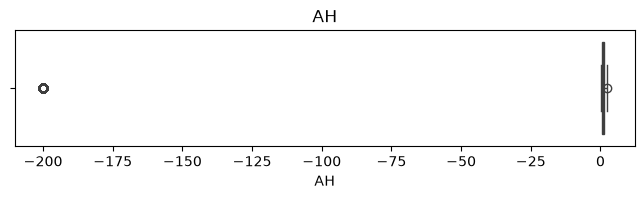

ValueError: List of boxplot statistics and `positions` values must have same the length

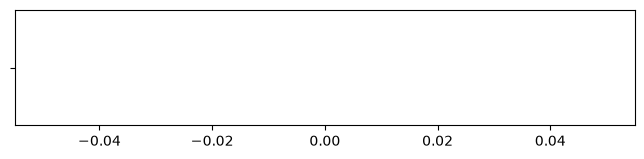

In [21]:
# Outliers
numeric_cols = df.select_dtypes(include="number").columns
for col in numeric_cols:

    plt.figure(figsize=(8, 1.5))

    sns.boxplot(
        x=df[col]
    )

    plt.title(col)
    plt.show()

In [22]:
def profile(series):
    observed = series.dropna()
    q1, q3 = observed.quantile([0.25, 0.75])
    return pd.Series({
        "n": observed.size,
        "missing": series.isna().sum(),
        "mean": observed.mean(),
        "median": observed.median(),
        "std": observed.std(),
        "IQR": q3 - q1,
        "min": observed.min(),
        "max": observed.max(),
        "skew": observed.skew()
    })

summary = df[["NOx(GT)", "NO2(GT)", "RH", "AH"]].apply(profile).T
display(summary)


,n,missing,mean,median,std,IQR,min,max,skew
NOx(GT),9357.0,114.0,168.616971,141.0000,257.433866,234.0000,-200.0,1479.000,0.825232
NO2(GT),9357.0,114.0,58.148873,96.0000,126.940455,80.0000,-200.0,340.000,-1.225630
RH,9357.0,114.0,39.485380,48.6000,51.216145,27.8000,-200.0,88.700,-3.932407
AH,9357.0,114.0,-6.837604,0.9768,38.976670,0.6039,-200.0,2.231,-4.754570
